In [0]:
!pip install pyspark

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%restart_python

In [0]:
print("Hello World!!!")

Hello World!!!


In [0]:
import pandas as pd

df = pd.read_csv("/Workspace/Users/azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com/Drafts/bookstore_orders_databricks.csv")
df.head()


,order_id,city,book_category,quantity,unit_price,order_status
0,1001,Hyderabad,Technology,2,850,Completed
1,1002,Bengaluru,Fiction,3,400,Completed
2,1003,Chennai,Science,1,650,Completed
3,1004,Hyderabad,Fiction,5,350,Completed
4,1005,Pune,History,2,500,Cancelled


In [0]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("Spark DataFrames").getOrCreate()

spark_df = spark.read.csv("/Workspace/Users/azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com/Drafts/bookstore_orders_databricks.csv", header=True, inferSchema=True)
spark_df.show()

+--------+---------+-------------+--------+----------+------------+
|order_id|     city|book_category|quantity|unit_price|order_status|
+--------+---------+-------------+--------+----------+------------+
|    1001|Hyderabad|   Technology|       2|       850|   Completed|
|    1002|Bengaluru|      Fiction|       3|       400|   Completed|
|    1003|  Chennai|      Science|       1|       650|   Completed|
|    1004|Hyderabad|      Fiction|       5|       350|   Completed|
|    1005|     Pune|      History|       2|       500|   Cancelled|
|    1006|Bengaluru|   Technology|       1|      1200|   Completed|
|    1007|  Chennai|      Fiction|       4|       300|   Completed|
|    1008|     Pune|      Science|       2|       750|   Completed|
|    1009|Hyderabad|      History|       3|       550|   Completed|
|    1010|Bengaluru|      Science|       2|       700|   Cancelled|
|    1011|  Chennai|   Technology|       2|       950|   Completed|
|    1012|     Pune|      Fiction|       1|     

In [0]:
spark_df.show(5)

+--------+---------+-------------+--------+----------+------------+
|order_id|     city|book_category|quantity|unit_price|order_status|
+--------+---------+-------------+--------+----------+------------+
|    1001|Hyderabad|   Technology|       2|       850|   Completed|
|    1002|Bengaluru|      Fiction|       3|       400|   Completed|
|    1003|  Chennai|      Science|       1|       650|   Completed|
|    1004|Hyderabad|      Fiction|       5|       350|   Completed|
|    1005|     Pune|      History|       2|       500|   Cancelled|
+--------+---------+-------------+--------+----------+------------+
only showing top 5 rows


In [0]:
%sql
CREATE OR REPLACE TABLE office_inventory_demo (
    product_id INT,
    product_name STRING,
    category STRING,
    city STRING,
    price INT,
    quantity INT
)
USING DELTA;

In [0]:
%sql
INSERT INTO office_inventory_demo VALUES
(101, 'Laptop', 'Electronics', 'Hyderabad', 55000, 10),
(102, 'Mouse', 'Accessories', 'Bengaluru', 800, 50),
(103, 'Keyboard', 'Accessories', 'Mumbai', 1500, 30),
(104, 'Monitor', 'Electronics', 'Hyderabad', 12000, 15),
(105, 'Office Chair', 'Furniture', 'Delhi', 6500, 20),
(106, 'Desk', 'Furniture', 'Chennai', 9000, 12),
(107, 'Printer', 'Electronics', 'Mumbai', 18000, 8),
(108, 'Webcam', 'Accessories', 'Hyderabad', 2500, 25),
(109, 'Projector', 'Electronics', 'Delhi', 45000, 5),
(110, 'Headphones', 'Accessories', 'Bengaluru', 3000, 40);


num_affected_rows,num_inserted_rows
10,10


In [0]:
%sql
SELECT * FROM office_inventory_demo;

product_id,product_name,category,city,price,quantity
101,Laptop,Electronics,Hyderabad,55000,10
102,Mouse,Accessories,Bengaluru,800,50
103,Keyboard,Accessories,Mumbai,1500,30
104,Monitor,Electronics,Hyderabad,12000,15
105,Office Chair,Furniture,Delhi,6500,20
106,Desk,Furniture,Chennai,9000,12
107,Printer,Electronics,Mumbai,18000,8
108,Webcam,Accessories,Hyderabad,2500,25
109,Projector,Electronics,Delhi,45000,5
110,Headphones,Accessories,Bengaluru,3000,40


In [0]:
%sql
UPDATE office_inventory_demo
SET price = 60000
WHERE product_id = 101;

num_affected_rows
1


In [0]:
%sql
UPDATE office_inventory_demo
SET price = 1000,
    quantity = 60
WHERE product_id = 102;

num_affected_rows
1


In [0]:
%sql
SELECT product_name, price
FROM office_inventory_demo;

product_name,price
Laptop,60000
Mouse,1000
Keyboard,1500
Monitor,12000
Office Chair,6500
Desk,9000
Printer,18000
Webcam,2500
Projector,45000
Headphones,3000


In [0]:
%sql
SELECT *
FROM office_inventory_demo

product_id,product_name,category,city,price,quantity
103,Keyboard,Accessories,Mumbai,1500,30
104,Monitor,Electronics,Hyderabad,12000,15
105,Office Chair,Furniture,Delhi,6500,20
106,Desk,Furniture,Chennai,9000,12
107,Printer,Electronics,Mumbai,18000,8
108,Webcam,Accessories,Hyderabad,2500,25
109,Projector,Electronics,Delhi,45000,5
110,Headphones,Accessories,Bengaluru,3000,40
102,Mouse,Accessories,Bengaluru,1000,60
101,Laptop,Electronics,Hyderabad,60000,10


### Creating Delta `Table`

In [0]:
%sql 
create or replace table retail_products_sql(
    product_id int,
    product_name string,
    price int
)
using delta;

In [0]:
%sql
insert into retail_products_sql values (1,'Laptop',20000),
(2,'Mobile',15000),
(3,'AC',30000),
(4,'TV',25000),
(5,'Refrigerator',40000);

num_affected_rows,num_inserted_rows
5,5


In [0]:
%sql
select * from retail_products_sql

product_id,product_name,price
1,Laptop,20000
2,Mobile,15000
3,AC,30000
4,TV,25000
5,Refrigerator,40000


## Using Spark

In [0]:
data = [
    (4, "Monitor", 12000),
    (5, "Printer", 18000),
    (6, "Webcam", 2500)
]
 
df = spark.createDataFrame(
    data,
    ["product_id", "product_name", "price"]
)
 
df.write \
    .format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable("retail_products_pyspark")
 
display(spark.table("retail_products_pyspark"))

product_id,product_name,price
4,Monitor,12000
5,Printer,18000
6,Webcam,2500


## Create Table as Select

In [0]:
%sql
CREATE OR REPLACE TABLE retail_products_ctas
USING DELTA
AS
SELECT *
FROM VALUES
    (7, 'Tablet', 25000),
    (8, 'Speaker', 5000),
    (9, 'Router', 3500)
AS products(product_id, product_name, price);

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT * FROM retail_products_ctas;

product_id,product_name,price
7,Tablet,25000
8,Speaker,5000
9,Router,3500


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW product_updates AS
SELECT *
FROM VALUES
    (2, 'Wireless Mouse', 950),
    (10, 'USB Hub', 1200)
AS updates(product_id, product_name, price);



MERGE INTO retail_products_sql AS target
USING product_updates AS source
ON target.product_id = source.product_id

WHEN MATCHED THEN
    UPDATE SET
        target.product_name = source.product_name,
        target.price = source.price

WHEN NOT MATCHED THEN
    INSERT (product_id, product_name, price)
    VALUES (source.product_id, source.product_name, source.price);
        

SELECT * FROM retail_products_sql
ORDER BY product_id;

product_id,product_name,price
1,Laptop,20000
2,Wireless Mouse,950
3,AC,30000
4,TV,25000
5,Refrigerator,40000
10,USB Hub,1200


In [0]:
%sql
describe detail retail_products_sql

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,c4831817-d3b8-43a3-adca-d7a4b17e782b,balaji_azure.default.retail_products_sql,null,abfss://unity-catalog-storage@dbstoragesd23buinind3a.dfs.core.windows.net/7405613151574717/__unitystorage/catalogs/cf9a2c09-1ac8-473b-a07d-5493da60eca2/tables/7163a7dc-ba02-425b-9306-fd7e16b38877,2026-11-05T10:46:25.494Z,2026-11-05T10:46:42.000Z,List(),List(),1,2222,"Map(delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, delta.enableRowTracking -> true, delta.checkpointPolicy -> v2, io.unitycatalog.tableId -> 7163a7dc-ba02-425b-9306-fd7e16b38877, delta.rowTracking.materializedRowCommitVersionColumnName -> _row-commit-version-col-b54a0b9a-8c58-43ef-883a-38ef7471d7ff, delta.rowTracking.materializedRowIdColumnName -> _row-id-col-9f0989bf-202c-4a58-b56f-c4365f69bf4a)",3,7,"List(appendOnly, clustering, deletionVectors, domainMetadata, invariants, rowTracking, v2Checkpoint)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",true


In [0]:
%sql
describe history retail_products_sql

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
7,2026-11-05T10:46:42.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(146054715566079),59de132b-6256-422f-b607-9bfc1df51cb0,1105-084817-jyzlbp39-v2n,6,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 5322, p25FileSize -> 2222, numDeletionVectorsRemoved -> 1, minFileSize -> 2222, numAddedFiles -> 1, maxFileSize -> 2222, p75FileSize -> 2222, p50FileSize -> 2222, numAddedBytes -> 2222)",null,Databricks-Runtime/19.13.x-photon-scala2.13
6,2026-11-05T10:46:40.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(product_id#22372 = product_id#22363)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}], clusteringOnWriteStatus -> null)",null,List(146054715566079),59de132b-6256-422f-b607-9bfc1df51cb0,1105-084817-jyzlbp39-v2n,5,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 2, numTargetBytesAdded -> 4009, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 1, executionTimeMs -> 2864, materializeSourceTimeMs -> 98, numTargetRowsInserted -> 1, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 946, numTargetRowsUpdated -> 1, numOutputRows -> 2, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1794)",null,Databricks-Runtime/19.13.x-photon-scala2.13
5,2026-11-05T10:46:27.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,WRITE,"Map(partitionBy -> [], clusterBy -> [], statsOnLoad -> true, mode -> Append, clusteringOnWriteStatus -> null)",null,List(146054715566079),f6003964-fcd9-40d1-be1c-199eacd23336,1105-084817-jyzlbp39-v2n,4,WriteSerializable,true,"Map(numFiles -> 1, numOutputRows -> 5, numOutputBytes -> 1313)",null,Databricks-Runtime/19.13.x-photon-scala2.13
4,2026-11-05T10:46:25.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,CREATE OR REPLACE TABLE,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""databricks.internal.autoUpgrades.delta.enableRowTracking"":""true"",""delta.enableDeletionVectors"":""true"",""databricks.internal.autoUpgrades.delta.checkpointPolicy"":""v2"",""databricks.internal.autoUpgrades.delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version"":""2.12.0"",""delta.enableRowTracking"":""true"",""delta.checkpointPolicy"":""v2"",""io.unitycatalog.tableId"":""7163a7dc-ba02-425b-9306-fd7e16b38877"",""delta.rowTracking.materializedRowCommitVersionColumnName"":""_row-commit-version-col-b54a0b9a-8c58-43ef-883a-38ef7471d7ff"",""delta.rowTracking.materializedRowIdColumnName"":""_row-id-col-9f0989bf-202c-4a58-b56f-c4365f69bf4a""}, statsOnLoad -> false, clusterByAuto -> true)",null,List(146054715566079),103c8322-28b0-4811-ab02-bc4e8811fac6,1105-084817-jyzlbp39-v2n,3,WriteSerializable,false,Map(),null,Databricks-Runtime/19.13.x-photon-scala2.13
3,2026-11-05T08:49:03.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(146054715566079),a48b0d5f-015f-4ae6-961c-b7ef8408a5cc,1105-084817-jyzlbp39-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 5322, p25FileSize -> 2222, numDeletionVectorsRemoved -> 1,

In [0]:
%sql
select * from retail_products_sql version as of 3

product_id,product_name,price
1,Laptop,20000
3,AC,30000
4,TV,25000
5,Refrigerator,40000
2,Wireless Mouse,950
10,USB Hub,1200


In [0]:
%sql 
optimize retail_products_sql;

path,metrics
abfss://unity-catalog-storage@dbstoragesd23buinind3a.dfs.core.windows.net/7405613151574717/__unitystorage/catalogs/cf9a2c09-1ac8-473b-a07d-5493da60eca2/tables/7163a7dc-ba02-425b-9306-fd7e16b38877,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, null, null, 0, 0, 1, 1, true, 0, 0, 1793875609120, 1793875609756, 8, 0, null, List(0, 0), null, 3, 3, 0, 0, null, null, 0)"


In [0]:
%sql
optimize retail_products_sql
zorder by (product_id)

path,metrics
abfss://unity-catalog-storage@dbstoragesd23buinind3a.dfs.core.windows.net/7405613151574717/__unitystorage/catalogs/cf9a2c09-1ac8-473b-a07d-5493da60eca2/tables/7163a7dc-ba02-425b-9306-fd7e16b38877,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, List(minCubeSize(107374182400), List(0, 0), List(1, 2222), 0, List(0, 0), 0, null), null, 0, 0, 1, 1, false, 0, 0, 1793875611515, 1793875612160, 8, 0, null, List(0, 0), null, 3, 3, 0, 0, null, null, 0)"


In [0]:
%sql
CREATE OR REPLACE TABLE cafe_orders_demo (
    order_id INT,
    customer_name STRING,
    city STRING,
    amount INT,
    order_status STRING
)
USING DELTA;

In [0]:
%sql
INSERT INTO cafe_orders_demo VALUES
(101, 'Ayaan', 'Hyderabad', 450, 'Completed'),
(102, 'Tara', 'Mumbai', 700, 'Pending'),
(103, 'Ishaan', 'Pune', 300, 'Completed'),
(104, 'Sara', 'Hyderabad', 900, 'Completed'),
(105, 'Kabir', 'Delhi', 250, 'Cancelled'),
(106, 'Zoya', 'Mumbai', 600, 'Pending'),
(107, 'Rehan', 'Pune', 800, 'Completed'),
(108, 'Mira', 'Delhi', 550, 'Completed');

num_affected_rows,num_inserted_rows
8,8


In [0]:
%sql
DESCRIBE EXTENDED cafe_orders_demo;

col_name,data_type,comment
order_id,int,null
customer_name,string,null
city,string,null
amount,int,null
order_status,string,null
# Clustering Information,,
# col_name,data_type,comment
,,
# Delta Statistics Columns,,
Column Names,"city, order_id, customer_name, amount, order_status",


In [0]:
%sql
show catalogs


catalog
balaji_azure
samples
system


In [0]:
%sql
use catalog balaji_azure

In [0]:
%sql
show schemas

databaseName
default
information_schema


In [0]:
%sql
show tables

database,tableName,isTemporary
default,cafe_orders_demo,false
default,cinema_bookings_cleaned,false
default,cinema_performance_report,false
default,courier_parcels_copy,false
default,courier_parcels_delta,false
default,courier_parcels_pyspark,false
default,fitness_memberships_demo,false
default,office_inventory_demo,false
default,retail_products_ctas,false
default,retail_products_pyspark,false


In [0]:
%sql
SHOW CURRENT SCHEMA 

catalog,namespace
balaji_azure,default


In [0]:
%sql
SELECT current_catalog()

current_catalog()
balaji_azure


In [0]:
%sql
CREATE OR REPLACE TABLE balaji_azure.default.bike_rides_raw (
    ride_id INT,
    station STRING,
    duration_min INT,
    fare DOUBLE,
    status STRING
)
USING DELTA;

In [0]:
%sql
INSERT INTO balaji_azure.default.bike_rides_raw VALUES
(1, 'Central', 20, 100.0, 'Completed'),
(2, 'Airport', 35, 180.0, 'Completed'),
(3, 'Metro', 15, 75.0, 'Cancelled'),
(4, 'Central', 40, 200.0, 'Completed'),
(5, 'University', 25, 125.0, 'Completed');

num_affected_rows,num_inserted_rows
5,5


In [0]:
%sql
SELECT * FROM balaji_azure.default.bike_rides_raw;

ride_id,station,duration_min,fare,status
1,Central,20,100.0,Completed
2,Airport,35,180.0,Completed
3,Metro,15,75.0,Cancelled
4,Central,40,200.0,Completed
5,University,25,125.0,Completed


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bike_bronze_sql
AS
SELECT *
FROM STREAM(balaji_azure.default.bike_rides_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bike_silver_sql
AS
SELECT
    ride_id,
    station,
    duration_min,
    fare
FROM STREAM(bike_bronze_sql)
WHERE status = 'Completed'
  AND duration_min > 0
  AND fare > 0;
 

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bike_silver_sql
AS
SELECT
    ride_id,
    station,
    duration_min,
    fare
FROM STREAM(bike_bronze_sql)
WHERE status = 'Completed'
  AND duration_min > 0
  AND fare > 0;

message
The operation was successfully executed.


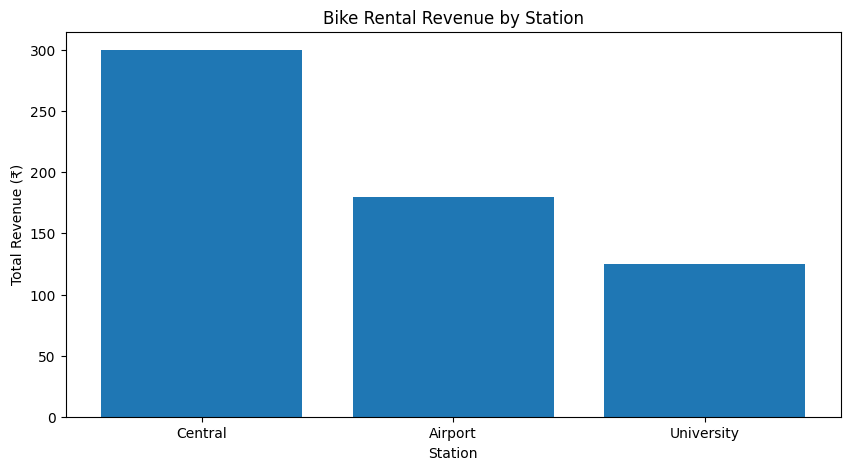

In [0]:
import matplotlib.pyplot as plt
df = spark.sql("""
    SELECT station, SUM(fare) AS total_revenue, COUNT(ride_id) AS total_rides
    FROM balaji_azure.default.bike_silver_sql GROUP BY station
""")
pdf = df.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(pdf["station"], pdf["total_revenue"])

plt.xlabel("Station")
plt.ylabel("Total Revenue (₹)")
plt.title("Bike Rental Revenue by Station")
plt.show()

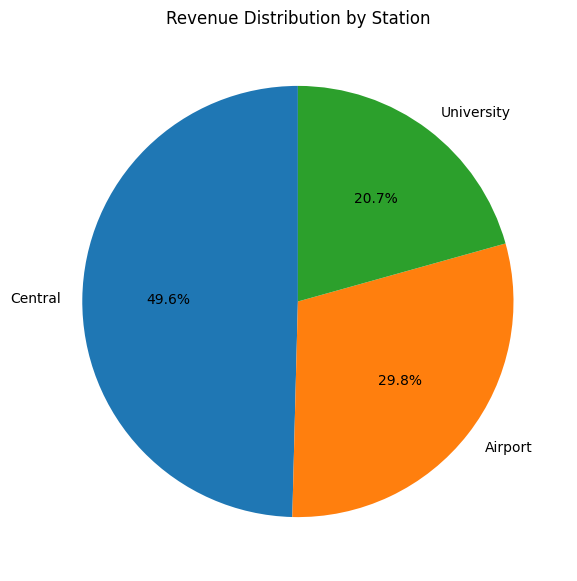

In [0]:
import matplotlib.pyplot as plt
df = spark.sql("""
    SELECT station, SUM(fare) AS total_revenue, COUNT(ride_id) AS total_rides
    FROM balaji_azure.default.bike_silver_sql GROUP BY station
""")
pdf = df.toPandas()

plt.figure(figsize=(7, 7))

plt.pie(
    pdf["total_revenue"],
    labels=pdf["station"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Station")
plt.show()

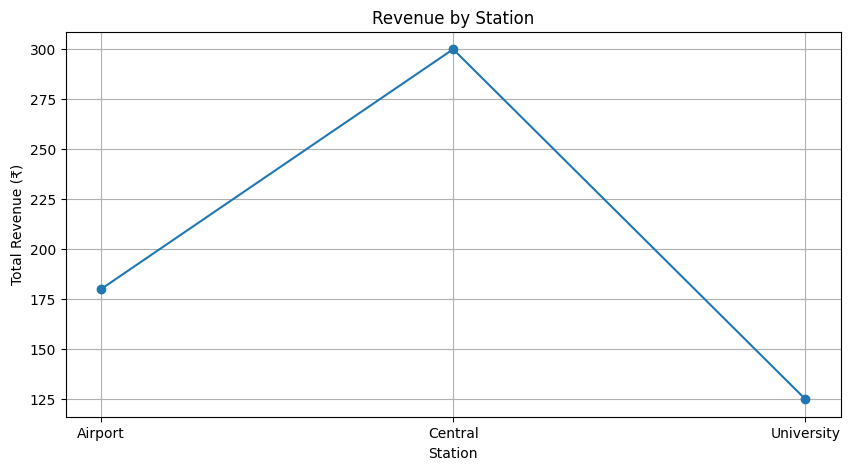

In [0]:
import matplotlib.pyplot as plt
df = spark.sql("""
    SELECT station, SUM(fare) AS total_revenue, COUNT(ride_id) AS total_rides
    FROM balaji_azure.default.bike_silver_sql GROUP BY station
""")
pdf = df.toPandas()

pdf = pdf.sort_values("station")

plt.figure(figsize=(10, 5))

plt.plot(
    pdf["station"],
    pdf["total_revenue"],
    marker="o"
)

plt.xlabel("Station")
plt.ylabel("Total Revenue (₹)")
plt.title("Revenue by Station")
plt.grid(True)
plt.show()  

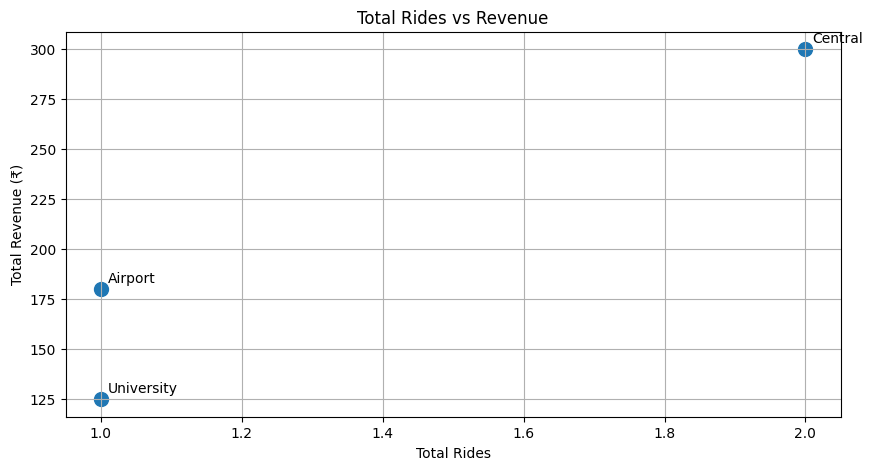

In [0]:
import matplotlib.pyplot as plt
df = spark.sql("""
    SELECT station, SUM(fare) AS total_revenue, COUNT(ride_id) AS total_rides
    FROM balaji_azure.default.bike_silver_sql GROUP BY station
""")
pdf = df.toPandas()
plt.figure(figsize=(10, 5))

plt.scatter(
    pdf["total_rides"],
    pdf["total_revenue"],
    s=100
)

for _, row in pdf.iterrows():
    plt.annotate(
        row["station"],
        (row["total_rides"], row["total_revenue"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Total Rides")
plt.ylabel("Total Revenue (₹)")
plt.title("Total Rides vs Revenue")
plt.grid(True)
plt.show()